# 03 · Baseline comparison
Logistic regression as the baseline against random forest and gradient boosting. Gradient boosting wins, but the baseline is only about 0.014 AUC behind it.

In [95]:
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [ ]:
X = pd.read_csv('../Data/processed/X_train_clean.csv')
y = pd.read_csv('../Data/processed/y_train.csv')

In [85]:
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')
X = X.fillna(-999)

In [86]:
X_train_clean, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


In [92]:
models = {
    'Logistics Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=94),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=94)
}

In [93]:
results = {}
for name, model in models.items():
    model.fit(X_train_clean, y_train)
    y_pred = model.predict_proba(X_val)[:, 1]
    score = roc_auc_score(y_val, y_pred)
    results[name] = score
    print(f"{name}: {score:.4f}")

sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Logistics Regression: 0.6915
Random Forest: 0.6801


sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Gradient Boosting: 0.7052


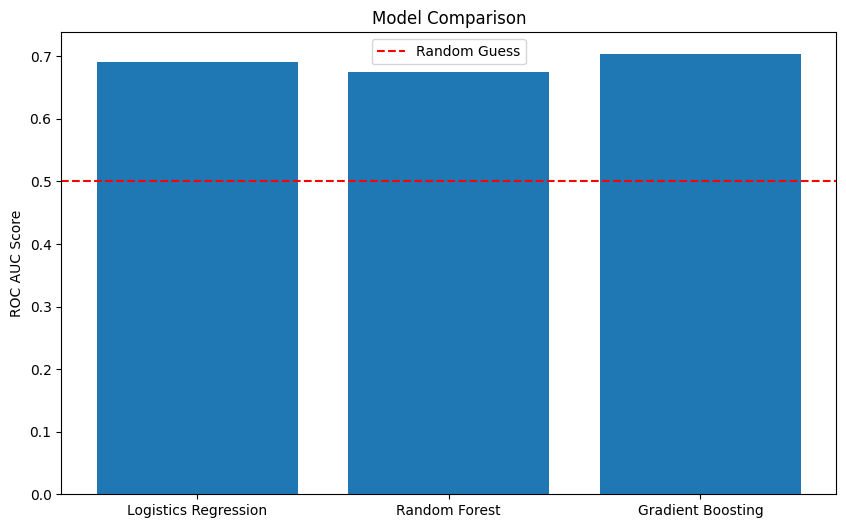

In [89]:
import matplotlib.pyplot as plt

# Bar chart
plt.figure(figsize=(10, 6))
plt.bar(results.keys(), results.values())
plt.ylabel('ROC AUC Score')
plt.title('Model Comparison')
plt.axhline(y=0.5, color='r', linestyle='--', label='Random Guess')
plt.legend()
plt.show()